In [37]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path().resolve().parents[0]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
    
    

from src.config import PROCESSED_DATA_DIR
from src.utils.plots import save_figure, style_plot, create_figure, add_bar_labels, add_source, YOUTUBE_RED, save_table, interpret_eta_squared, DARK_RED
import pandas as pd

In [38]:
df = pd.read_csv(PROCESSED_DATA_DIR / "youtube_clean.csv")
df.head()


,video_id,title,description,published_at,category_id,tags,duration,channel_id,channel_title,views,...,hour,day_of_week,duration_seconds,duration_minutes,is_short,duration_group,is_viral,tag_count,has_tags,category_name
0,ELkyDvO-j6Q,treat u right,Provided to YouTube by EMPIRE Distribution\n\n...,2026-07-02 22:11:35+00:00,10,"['FOLA', 'Ayra Starr', 'treat u right']",PT2M58S,UC4mHpkf_26sEWN8M5PMpV_w,FOLA - Topic,120661,...,22,3,178,2.97,0,1-5 mins,0,3,True,Music
1,hMlHf-YXVUM,ALAKADA GEN Z 3 (Official Trailer) | Latest Ni...,ALAKADA GEN Z 3 Official Trailer is here! 🎬😂 \...,2026-07-05 17:00:39+00:00,24,"['Alakada Gen Z 3', 'Alakada Gen Z 3 trailer',...",PT2M33S,UCoSnFVOBlcdgjSUETGd65kA,Toyin Abraham TV,69067,...,17,6,153,2.55,0,1-5 mins,0,23,True,Entertainment
2,BaO6Dnxquv8,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,2026-07-05 20:06:24+00:00,20,"['gta 5 live', 'gta v live stream', 'gta 5 gam...",PT31M8S,UC9OTne2HnCn_kkyx8NodI-g,Pixel Hunters,14163447,...,20,6,1868,31.13,0,15-60 mins,1,25,True,Gaming
3,KkDHSWq7XGw,Jorja Smith - Alive feat. Wizkid,Jorja Smith - Alive feat. Wizkid - Out now: ht...,2026-07-02 16:00:27+00:00,10,"['jorja smith', 'alive', 'wizkid', 'what are t...",PT3M31S,UCHA6dVPvxRdLQ5Uu-uX3MLw,Jorja Smith,952264,...,16,3,211,3.52,0,1-5 mins,0,5,True,Music
4,DVHPZ36Sav8,IYE Latest Yoruba Movie 2026 l Official Traile...,Some homes don’t let you leave…\nAnd if you do...,2026-06-29 17:00:24+00:00,22,[],PT1M28S,UCi00_82Wh1q_rm2Yz8m7GIA,THE DAMILOLA ONI TV,72623,...,17,0,88,1.47,0,1-5 mins,0,0,False,People & Blogs


In [39]:
# is_viral is what we intend to predict, we will drop every variable that maybe a leakage to our model
# engagement rate, log views, likes, comments and shares

df["published_at"] = pd.to_datetime(df["published_at"])

df["publication_hour"] = df["published_at"].dt.hour
df["publication_weekday"] = df["published_at"].dt.dayofweek
df["publication_weekday_name"] = df["published_at"].dt.day_name()

def classify_publication_period(hour):
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"


df["publication_period"] = df["publication_hour"].apply(
    classify_publication_period
)

print(df['publication_hour'].head(3), df['publication_weekday'].head(3), df['publication_weekday_name'].head(3))


0    22
1    17
2    20
Name: publication_hour, dtype: int32 0    3
1    6
2    6
Name: publication_weekday, dtype: int32 0    Thursday
1      Sunday
2      Sunday
Name: publication_weekday_name, dtype: str


In [40]:
# convert duration to seconds
import re

def duration_to_seconds(duration):
    match = re.fullmatch(
        r"PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?",
        duration
    )

    if not match:
        return None

    hours = int(match.group(1) or 0)
    minutes = int(match.group(2) or 0)
    seconds = int(match.group(3) or 0)

    return hours * 3600 + minutes * 60 + seconds


df["duration_seconds"] = df["duration"].apply(duration_to_seconds)
print(df[["duration", "duration_seconds"]].head(10))

   duration  duration_seconds
0   PT2M58S             178.0
1   PT2M33S             153.0
2   PT31M8S            1868.0
3   PT3M31S             211.0
4   PT1M28S              88.0
5  PT33M39S            2019.0
6   PT3M58S             238.0
7   PT2M12S             132.0
8  PT18M15S            1095.0
9   PT3M54S             234.0


In [41]:
# create target and feature variables
features = [
    "category_name",
    "duration_seconds",
    "tag_count",
    "has_tags",
    "publication_hour",
    "publication_weekday",
    "publication_period",
]

X = df[features].copy()
y = df["is_viral"].copy()

print(X.shape)
print(y.shape)

(17249, 7)
(17249,)


In [42]:
# train test split
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


# check the split count distribution
print("Training:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nValidation:")
print(y_val.value_counts())
print(y_val.value_counts(normalize=True))

print("\nTest:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

Training set: (12074, 7)
Validation set: (2587, 7)
Test set: (2588, 7)
Training:
is_viral
0    10867
1     1207
Name: count, dtype: int64
is_viral
0    0.900033
1    0.099967
Name: proportion, dtype: float64

Validation:
is_viral
0    2328
1     259
Name: count, dtype: int64
is_viral
0    0.899884
1    0.100116
Name: proportion, dtype: float64

Test:
is_viral
0    2329
1     259
Name: count, dtype: int64
is_viral
0    0.899923
1    0.100077
Name: proportion, dtype: float64


In [43]:
# preprocessing features
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "duration_seconds",
    "tag_count"
]

categorical_features = [
    "category_name",
    "publication_hour",
    "publication_weekday",
    "publication_period",
]

binary_features = [
    "has_tags"
]


numeric_transformer = SimpleImputer(
    strategy="median",
    add_indicator=True
)


categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
     drop="first"
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            ),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ]
)

In [44]:
# fit data
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)


print("Training missing values:", X_train.isna().sum())
print('-----')

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)
print("Test processed shape:", X_test_processed.shape)

Training missing values: category_name           0
duration_seconds       40
tag_count               0
has_tags                0
publication_hour        0
publication_weekday     0
publication_period      0
dtype: int64
-----
Training processed shape: (12074, 50)
Validation processed shape: (2587, 50)
Test processed shape: (2588, 50)


In [45]:
# calculate baseline, since 90% of data is non viral setting baseline to non viral is already 90% accurate
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train_processed, y_train)

baseline_predictions = baseline.predict(X_test_processed)



print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline Precision:",
      precision_score(
          y_test,
          baseline_predictions,
          zero_division=0
      ))

print("Baseline Recall:",
      recall_score(
          y_test,
          baseline_predictions,
          zero_division=0
      ))

print("Baseline F1:",
      f1_score(
          y_test,
          baseline_predictions,
          zero_division=0
      ))

Baseline Accuracy: 0.8999227202472952
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1: 0.0


In [46]:
# create a logistic regression model that predicts given the characteristic of a video the possibility that that video belongs to the top 10 vissibile content

from sklearn.linear_model import LogisticRegression


logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

/Users/pro2020/projects/python/social-media-algorithm-analysis/social_media_analyis_venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [47]:
# prediction
y_val_pred = logistic_model.predict(X_val_processed)

y_val_prob = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

In [48]:
# evaluate the prediction
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Logistic Regression Results")
print("----------------------------")

print(
    "Accuracy:",
    accuracy_score(y_val, y_val_pred)
)

print(
    "Precision:",
    precision_score(
        y_val,
        y_val_pred,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_val,
        y_val_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_val,
        y_val_pred,
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_val,
        y_val_prob
    )
)

Logistic Regression Results
----------------------------
Accuracy: 0.9002705836876691
Precision: 1.0
Recall: 0.003861003861003861
F1: 0.007692307692307693
ROC-AUC: 0.714402639016041


In [49]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    y_val_pred
)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[2328    0]
 [ 258    1]]


In [50]:
# which characteristics or features most contribute in predicting virality
feature_names = preprocessor.get_feature_names_out()

coefficients = logistic_model.coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_df["absolute_coefficient"] = (
    coef_df["coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "absolute_coefficient",
    ascending=False
)

print(coef_df.head(20))

                                   feature  coefficient  absolute_coefficient
10      cat__category_name_News & Politics    -1.988882              1.988882
9                 cat__category_name_Music     1.092045              1.092045
16      cat__category_name_Travel & Events    -0.991488              0.991488
8         cat__category_name_Howto & Style    -0.891096              0.891096
19                 cat__publication_hour_3    -0.832047              0.832047
6      cat__category_name_Film & Animation     0.820079              0.820079
2   num__missingindicator_duration_seconds    -0.727927              0.727927
12       cat__category_name_People & Blogs    -0.642355              0.642355
18                 cat__publication_hour_2    -0.580211              0.580211
44              cat__publication_weekday_5    -0.511138              0.511138
3                cat__category_name_Comedy     0.461698              0.461698
46         cat__publication_period_Evening    -0.432428         

In [51]:
print(
    df.groupby("publication_weekday")["log_views"]
      .count()
)

print(
    df[["publication_weekday"]]
      .drop_duplicates()
      .sort_values("publication_weekday")
)

print(
    df[["publication_hour"]]
      .drop_duplicates()
      .sort_values("publication_hour")
)

publication_weekday
0    1893
1    2020
2    2051
3    2436
4    3069
5    3129
6    2651
Name: log_views, dtype: int64
    publication_weekday
4                     0
9                     1
28                    2
0                     3
6                     4
16                    5
1                     6
     publication_hour
79                  0
31                  1
38                  2
10                  3
40                  4
63                  5
94                  6
7                   7
25                  8
113                 9
15                 10
48                 11
5                  12
14                 13
88                 14
8                  15
3                  16
1                  17
24                 18
43                 19
2                  20
92                 21
0                  22
9                  23


In [53]:
# test different thresholds

import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.10, 0.51, 0.05)

results = []

for threshold in thresholds:

    predictions = (
        y_val_prob >= threshold
    ).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_val,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_val,
            predictions,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print(threshold_results)

   threshold  precision    recall        f1
0       0.10   0.178492  0.621622  0.277347
1       0.15   0.218579  0.463320  0.297030
2       0.20   0.278287  0.351351  0.310580
3       0.25   0.350000  0.270270  0.305011
4       0.30   0.395161  0.189189  0.255875
5       0.35   0.456790  0.142857  0.217647
6       0.40   0.500000  0.065637  0.116041
7       0.45   0.500000  0.027027  0.051282
8       0.50   1.000000  0.003861  0.007692


In [54]:
# finding the optimal threshold
thresholds = np.arange(0.01, 0.51, 0.01)

results = []

for threshold in thresholds:

    predictions = (
        y_val_prob >= threshold
    ).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_val,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_val,
            predictions,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

best_threshold = threshold_results.loc[
    threshold_results["f1"].idxmax()
]

print(best_threshold)

threshold    0.210000
precision    0.296928
recall       0.335907
f1           0.315217
Name: 20, dtype: float64


In [55]:
#  use the best threshold to test
best_threshold = 0.21

y_test_prob = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)


print("Final Test Results")
print("------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, y_test_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        y_test_pred,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        y_test_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        y_test_pred,
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        y_test_prob
    )
)

Final Test Results
------------------
Accuracy: 0.8616692426584235
Precision: 0.3333333333333333
Recall: 0.38223938223938225
F1: 0.35611510791366907
ROC-AUC: 0.760476848068089


In [56]:
cm_test = confusion_matrix(
    y_test,
    y_test_pred
)

print("Test Confusion Matrix:")
print(cm_test)

Test Confusion Matrix:
[[2131  198]
 [ 160   99]]


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q4/roc_curve.png


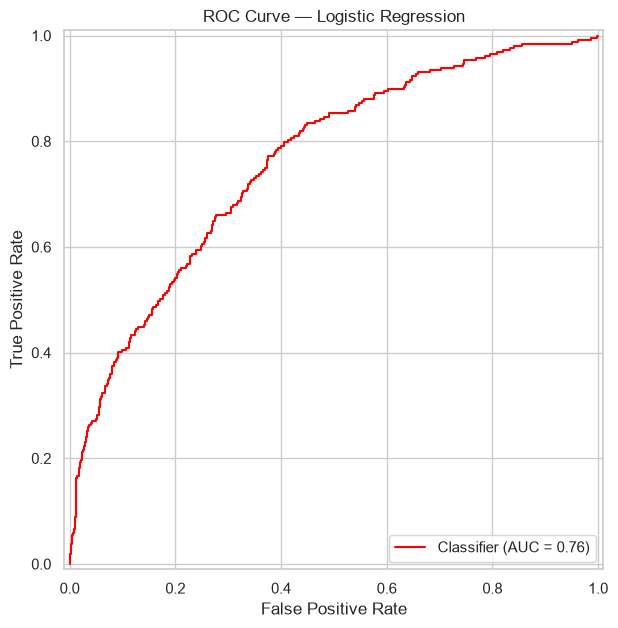

<Figure size 640x480 with 0 Axes>

In [70]:
from sklearn.metrics import RocCurveDisplay

fig, ax = create_figure()

RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob,
    ax=ax,
    curve_kwargs={"color": "red"},
    

)

ax.set_title("ROC Curve — Logistic Regression")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

save_figure(
    fig=fig,
    filename="q4/roc_curve.png",
   
)

plt.show()
plt.clf()

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q4/precision_recall_curve.png


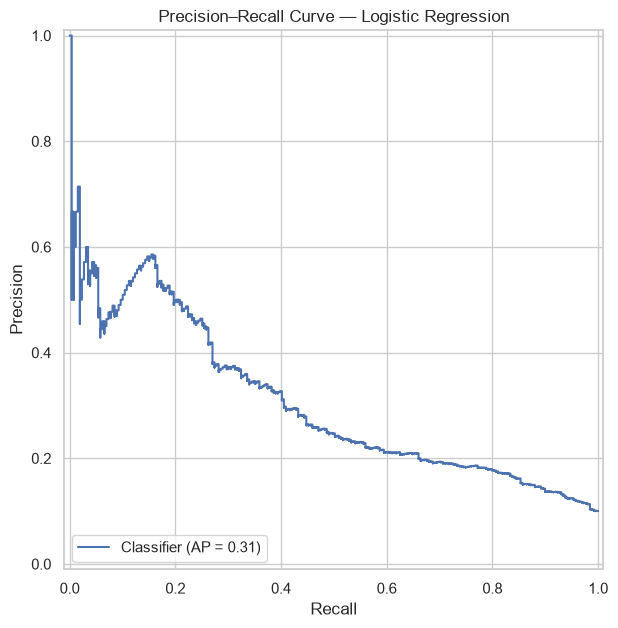

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = create_figure()

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob,
    ax=ax,
    curve_kwargs={"color": "red"},
)

ax.set_title("Precision–Recall Curve — Logistic Regression")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

save_figure(
    fig=fig,
    filename="q4/precision_recall_curve.png"
)

plt.show()
plt.clf()

In [59]:
# Get feature names from the preprocessing pipeline
feature_names = preprocessor.get_feature_names_out()

# Get logistic regression coefficients
coefficients = logistic_model.coef_[0]

# Create a dataframe
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Add absolute coefficient for ranking
feature_importance["absolute_coefficient"] = (
    feature_importance["coefficient"].abs()
)

# Sort by absolute coefficient
feature_importance = feature_importance.sort_values(
    "absolute_coefficient",
    ascending=False
)

print(feature_importance.head(20))

                                   feature  coefficient  absolute_coefficient
10      cat__category_name_News & Politics    -1.988882              1.988882
9                 cat__category_name_Music     1.092045              1.092045
16      cat__category_name_Travel & Events    -0.991488              0.991488
8         cat__category_name_Howto & Style    -0.891096              0.891096
19                 cat__publication_hour_3    -0.832047              0.832047
6      cat__category_name_Film & Animation     0.820079              0.820079
2   num__missingindicator_duration_seconds    -0.727927              0.727927
12       cat__category_name_People & Blogs    -0.642355              0.642355
18                 cat__publication_hour_2    -0.580211              0.580211
44              cat__publication_weekday_5    -0.511138              0.511138
3                cat__category_name_Comedy     0.461698              0.461698
46         cat__publication_period_Evening    -0.432428         

In [60]:
for transformer_name, transformer, columns, *_ in preprocessor.transformers_:
    if transformer_name == "cat":
        # 'transformer' is already the OneHotEncoder instance
        encoder = transformer

        print("Categorical features:")
        print(columns)

        print("\nCategories:")
        for column, categories in zip(columns, encoder.categories_):
            print(column, ":", categories)

Categorical features:
['category_name', 'publication_hour', 'publication_weekday', 'publication_period']

Categories:
category_name : ['Autos & Vehicles' 'Comedy' 'Education' 'Entertainment'
 'Film & Animation' 'Gaming' 'Howto & Style' 'Music' 'News & Politics'
 'Nonprofits' 'People & Blogs' 'Pets & Animals' 'Science & Tech' 'Sports'
 'Travel & Events']
publication_hour : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
publication_weekday : [0 1 2 3 4 5 6]
publication_period : ['Afternoon' 'Evening' 'Morning' 'Night']


In [67]:
import numpy as np

feature_importance["odds_ratio"] = np.exp(
    feature_importance["coefficient"]
)

print(feature_importance[
    [
        "feature",
        "coefficient",
        "odds_ratio"
    ]
].head(20))



                                   feature  coefficient  odds_ratio
10      cat__category_name_News & Politics    -1.988882    0.136848
9                 cat__category_name_Music     1.092045    2.980362
16      cat__category_name_Travel & Events    -0.991488    0.371024
8         cat__category_name_Howto & Style    -0.891096    0.410206
19                 cat__publication_hour_3    -0.832047    0.435158
6      cat__category_name_Film & Animation     0.820079    2.270678
2   num__missingindicator_duration_seconds    -0.727927    0.482909
12       cat__category_name_People & Blogs    -0.642355    0.526052
18                 cat__publication_hour_2    -0.580211    0.559780
44              cat__publication_weekday_5    -0.511138    0.599813
3                cat__category_name_Comedy     0.461698    1.586766
46         cat__publication_period_Evening    -0.432428    0.648932
30                cat__publication_hour_14    -0.408791    0.664453
7                cat__category_name_Gaming    -0

In [62]:
positive_features = feature_importance[
    feature_importance["coefficient"] > 0
].sort_values(
    "coefficient",
    ascending=False
)

print(
    positive_features[
        ["feature", "coefficient", "odds_ratio"]
    ].head(15)
)

                                feature  coefficient  odds_ratio
9              cat__category_name_Music     1.092045    2.980362
6   cat__category_name_Film & Animation     0.820079    2.270678
3             cat__category_name_Comedy     0.461698    1.586766
49                     binary__has_tags     0.384766    1.469270
15            cat__category_name_Sports     0.360299    1.433758
27             cat__publication_hour_11     0.286207    1.331368
34             cat__publication_hour_18     0.203753    1.225995
20              cat__publication_hour_4     0.112067    1.118588
40           cat__publication_weekday_1     0.095002    1.099661
38             cat__publication_hour_22     0.076043    1.079009
33             cat__publication_hour_17     0.067211    1.069522
25              cat__publication_hour_9     0.056349    1.057967
5      cat__category_name_Entertainment     0.035630    1.036273
1                        num__tag_count     0.027140    1.027512
41           cat__publica

In [63]:
negative_features = feature_importance[
    feature_importance["coefficient"] < 0
].sort_values(
    "coefficient",
    ascending=True
)

print(
    negative_features[
        ["feature", "coefficient", "odds_ratio"]
    ].head(15)
)

                                   feature  coefficient  odds_ratio
10      cat__category_name_News & Politics    -1.988882    0.136848
16      cat__category_name_Travel & Events    -0.991488    0.371024
8         cat__category_name_Howto & Style    -0.891096    0.410206
19                 cat__publication_hour_3    -0.832047    0.435158
2   num__missingindicator_duration_seconds    -0.727927    0.482909
12       cat__category_name_People & Blogs    -0.642355    0.526052
18                 cat__publication_hour_2    -0.580211    0.559780
44              cat__publication_weekday_5    -0.511138    0.599813
46         cat__publication_period_Evening    -0.432428    0.648932
30                cat__publication_hour_14    -0.408791    0.664453
7                cat__category_name_Gaming    -0.405441    0.666683
26                cat__publication_hour_10    -0.396890    0.672408
39                cat__publication_hour_23    -0.392040    0.675677
4             cat__category_name_Education    -0

In [64]:
category_results = feature_importance[
    feature_importance["feature"].str.startswith(
        "cat__category_name_"
    )
].copy()

category_results["category"] = (
    category_results["feature"]
    .str.replace(
        "cat__category_name_",
        "",
        regex=False
    )
)

category_results = category_results.sort_values(
    "coefficient",
    ascending=False
)

print(
    category_results[
        ["category", "coefficient", "odds_ratio"]
    ].to_string(index=False)
)

        category  coefficient  odds_ratio
           Music     1.092045    2.980362
Film & Animation     0.820079    2.270678
          Comedy     0.461698    1.586766
          Sports     0.360299    1.433758
   Entertainment     0.035630    1.036273
  Pets & Animals    -0.006003    0.994015
      Nonprofits    -0.122567    0.884646
  Science & Tech    -0.172389    0.841652
       Education    -0.377156    0.685809
          Gaming    -0.405441    0.666683
  People & Blogs    -0.642355    0.526052
   Howto & Style    -0.891096    0.410206
 Travel & Events    -0.991488    0.371024
 News & Politics    -1.988882    0.136848


In [66]:
temporal_results = feature_importance[
    feature_importance["feature"].str.startswith(
        "cat__publication_"
    )
].copy()

temporal_results["feature"] = (
    temporal_results["feature"]
    .str.replace("cat__publication_", "", regex=False)
)

temporal_results = temporal_results.sort_values(
    "coefficient",
    ascending=False
)

print(
    temporal_results[
        ["feature", "coefficient", "odds_ratio"]
    ].to_string(index=False)
)

       feature  coefficient  odds_ratio
       hour_11     0.286207    1.331368
       hour_18     0.203753    1.225995
        hour_4     0.112067    1.118588
     weekday_1     0.095002    1.099661
       hour_22     0.076043    1.079009
       hour_17     0.067211    1.069522
        hour_9     0.056349    1.057967
     weekday_2     0.018587    1.018761
       hour_20     0.012181    1.012255
        hour_5    -0.000354    0.999646
        hour_7    -0.032444    0.968076
       hour_16    -0.043790    0.957155
        hour_6    -0.070335    0.932082
       hour_12    -0.079955    0.923158
        hour_8    -0.098408    0.906279
       hour_15    -0.112055    0.893995
        hour_1    -0.133624    0.874919
       hour_21    -0.141976    0.867642
     weekday_3    -0.157023    0.854685
       hour_19    -0.190387    0.826639
     weekday_4    -0.199813    0.818884
period_Morning    -0.255522    0.774512
       hour_13    -0.270788    0.762778
     weekday_6    -0.282323    0.754030
